IMPORTAZIONE LIBRERIE PRINCIPALI

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

In [2]:
# 1. Importo il file CSV
# Nota: L'Online Retail dataset spesso usa un encoding diverso dall'UTF-8 standard
df = pd.read_csv('Online_Retail.csv')

# 2. Visualizzo le prime 5 righe per verificare che l'importazione sia andata a buon fine
display(df.head())

# 3. Controllo subito le dimensioni del dataset e i tipi di dato
print("\nInformazioni sul dataset:")
df.info()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Informazioni sul dataset:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [3]:
# 1. Rimuovo le transazioni annullate o i resi
# Nel dataset i resi hanno un InvoiceNo (Numero Fattura) che inizia con la lettera 'C'.
# Mi assicuro che la colonna sia in formato stringa, poi filtro tenendo solo le righe che NON iniziano con 'C' (simbolo ~ per negare la condizione)
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df_clean = df[~df['InvoiceNo'].str.startswith('C')]

# 2. Elimino quantità e prezzi anomali
# Un ordine non può avere una quantità zero o negativa, e il prezzo non può essere gratuito o negativo.
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]

# 3. Gestisco i valori mancanti (NaN)
# Verifico quanti dati mancano prima di procedere
print("Valori nulli per colonna:\n", df_clean.isnull().sum())

# Sapere "chi" compra è importante. Rimuovo le righe senza CustomerID.
df_clean = df_clean.dropna(subset=['CustomerID'])

# Converto il CustomerID in un numero intero (spesso viene letto come decimale se ci sono NaN)
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

# 4. Sanity Check Finale
print("\nDimensioni del dataset pulito:", df_clean.shape)

Valori nulli per colonna:
 InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132220
Country             0
dtype: int64

Dimensioni del dataset pulito: (397884, 8)


--- TOP 5 PRODOTTI PER FATTURATO ---
Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142592.95
WHITE HANGING HEART T-LIGHT HOLDER    100448.15
JUMBO BAG RED RETROSPOT                85220.78
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
Name: Revenue, dtype: float64


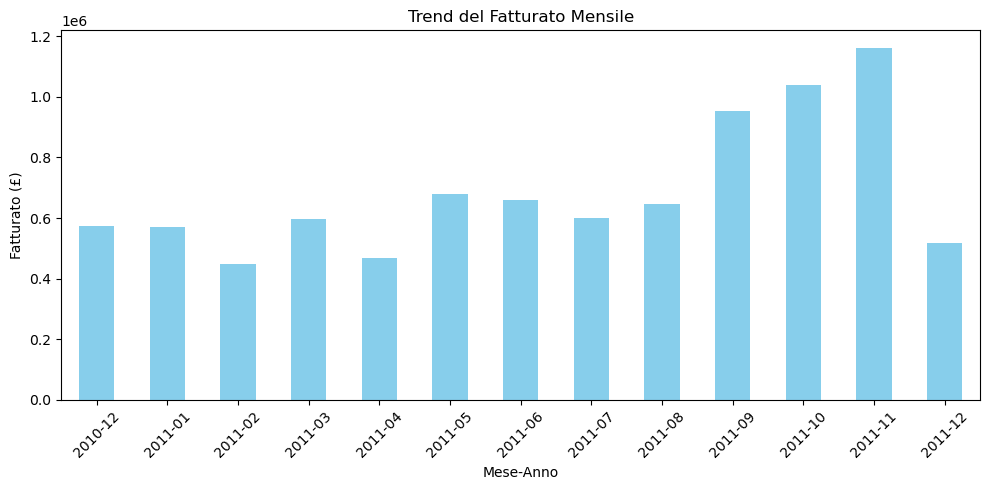

In [4]:
# 1. Forzo la colonna InvoiceDate a formato data (risolvo il problema del tipo 'str')
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# 2. Creo la colonna "Revenue" (Fatturato totale per singola riga)
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['UnitPrice']

# 3. Creo una colonna per il Mese-Anno per analizzare i trend
df_clean['MonthYear'] = df_clean['InvoiceDate'].dt.to_period('M')

# 4. Calcolo il fatturato totale per ogni mese
monthly_revenue = df_clean.groupby('MonthYear')['Revenue'].sum()

# 5. Trovo i 5 prodotti che hanno generato più fatturato in assoluto
top_5_products = df_clean.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(5)

# STAMPO I RISULTATI DI BUSINESS
print("--- TOP 5 PRODOTTI PER FATTURATO ---")
print(top_5_products)

# Visualizzo il trend mensile delle vendite
plt.figure(figsize=(10, 5))
monthly_revenue.plot(kind='bar', color='skyblue')
plt.title('Trend del Fatturato Mensile')
plt.xlabel('Mese-Anno')
plt.ylabel('Fatturato (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
# 1. Rimuovo il mese incompleto (Dicembre 2011)
df_model = df_clean[df_clean['InvoiceDate'] < '2011-12-01'].copy()

# 2. Estraggo solo la data (senza l'orario) per raggruppare le vendite giornaliere
df_model['Date'] = df_model['InvoiceDate'].dt.date

# 3. Aggregazione: voglio sapere la quantità totale venduta ogni giorno
daily_sales = df_model.groupby('Date')['Quantity'].sum().reset_index()
daily_sales['Date'] = pd.to_datetime(daily_sales['Date'])

# 4. Feature Engineering: Creo colonne per far "capire" il tempo al modello
daily_sales['DayOfWeek'] = daily_sales['Date'].dt.dayofweek # 0=Lunedì, 6=Domenica
daily_sales['Month'] = daily_sales['Date'].dt.month
daily_sales['IsWeekend'] = daily_sales['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)

# 5. Variabile target (Y) e variabili indipendenti (X)
print("Preview del dataset pronto per il Machine Learning:")
display(daily_sales.head())
print("\nDimensioni dataset giornaliero:", daily_sales.shape)

Preview del dataset pronto per il Machine Learning:


,Date,Quantity,DayOfWeek,Month,IsWeekend
0,2010-12-01,24215,2,12,0
1,2010-12-02,31142,3,12,0
2,2010-12-03,11839,4,12,0
3,2010-12-05,16449,6,12,1
4,2010-12-06,16291,0,12,0



Dimensioni dataset giornaliero: (297, 5)


--- RISULTATI DEL MODELLO ---
Media vendite giornaliere: 16432 unità
Errore Medio Assoluto (MAE): 8357 unità


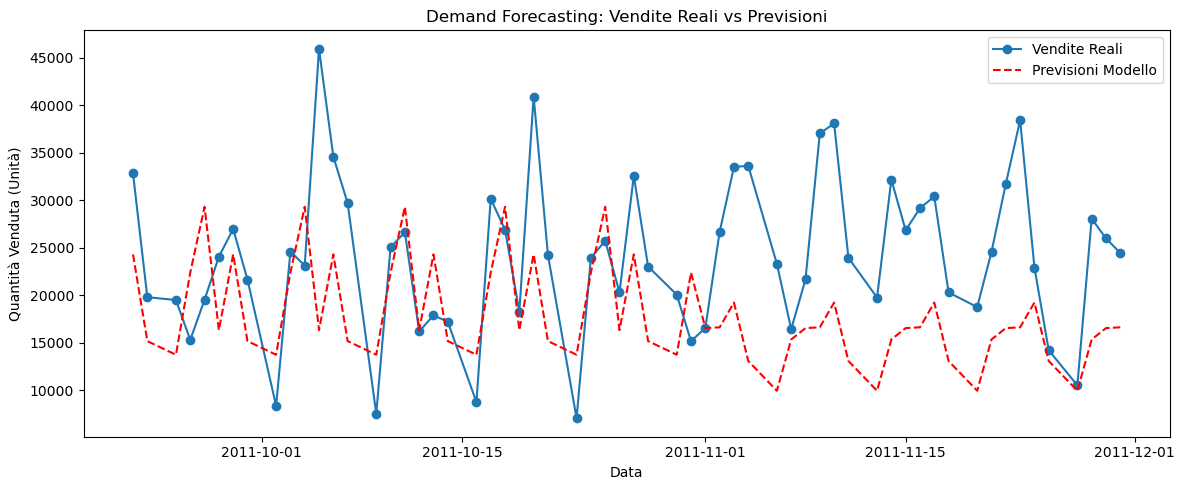

In [6]:
# 1. Definisco le Features (X) e il Target da prevedere (y)
X = daily_sales[['DayOfWeek', 'Month', 'IsWeekend']]
y = daily_sales['Quantity']

# 2. Divido i dati: Training Set (80%) per imparare, Test Set (20%) per verificare
# IMPORTANTE: shuffle=False perché con i dati temporali non posso mischiare le date 
# Voglio addestrare il modello sul passato per prevedere il futuro.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# 3. Inizializzo e addestro il modello (creo 100 "alberi decisionali")
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 4. Chiedo al modello di prevedere le vendite sul 20% di dati che non ha mai visto (Test Set)
predictions = model.predict(X_test)

# 5. Valuto le performance con il Mean Absolute Error (MAE)
mae = mean_absolute_error(y_test, predictions)
media_vendite_giornaliere = y.mean()

print(f"--- RISULTATI DEL MODELLO ---")
print(f"Media vendite giornaliere: {media_vendite_giornaliere:.0f} unità")
print(f"Errore Medio Assoluto (MAE): {mae:.0f} unità")

# 6. Plot: Confronto visivamente la realtà con le previsioni
plt.figure(figsize=(12, 5))
plt.plot(daily_sales['Date'].iloc[y_test.index], y_test, label='Vendite Reali', marker='o')
plt.plot(daily_sales['Date'].iloc[y_test.index], predictions, label='Previsioni Modello', color='red', linestyle='--')
plt.title('Demand Forecasting: Vendite Reali vs Previsioni')
plt.xlabel('Data')
plt.ylabel('Quantità Venduta (Unità)')
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
# 1. Creo un DataFrame con le date del test, le vendite reali e le previsioni
results_df = pd.DataFrame({
    'Date': daily_sales['Date'].iloc[y_test.index],
    'Vendite_Reali': y_test,
    'Previsioni': predictions
})

# 2. Esporto in CSV per Power BI con formattazione europea
# Aggiungo decimal=',' e sep=';' per risolvere il problema dei grandi numeri in Power BI
results_df.to_csv('Forecast_Results.csv', index=False, decimal=',', sep=';')
df_clean.to_csv('Historical_Sales.csv', index=False, decimal=',', sep=';')

print("File esportati con successo in formato europeo! Pronti per Power BI.")

File esportati con successo in formato europeo! Pronti per Power BI.
